Load EIS Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

# Load CSV
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# Convert strings to complex numbers
def str_to_complex(s):
    s = s.replace('i', 'j')
    return complex(s)

# Convert each column using map
impedance_data = df.apply(lambda col: col.map(str_to_complex))
print("Loaded EIS Data Shape:", impedance_data.shape)


# Define Low-Pass Filter function
def low_pass_filter(signal, alpha=0.1):
    filtered = np.zeros_like(signal, dtype=complex)
    filtered[0] = signal[0]
    for i in range(1, len(signal)):
        filtered[i] = alpha * signal[i] + (1 - alpha) * filtered[i-1]
    return filtered

# Apply LPF to each row
filtered_data = impedance_data.apply(lambda row: low_pass_filter(np.array(row)), axis=1)

# Save filtered_data to .pkl file
with open('filtered_data.pkl', 'wb') as f:
    pickle.dump(filtered_data, f)

print("Saved filtered_data.pkl")

Loaded EIS Data Shape: (14, 10)
Saved filtered_data.pkl


Nyquist Plot

C:\Users\Hp\AppData\Local\Temp\ipykernel_26236\2459145689.py:14: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


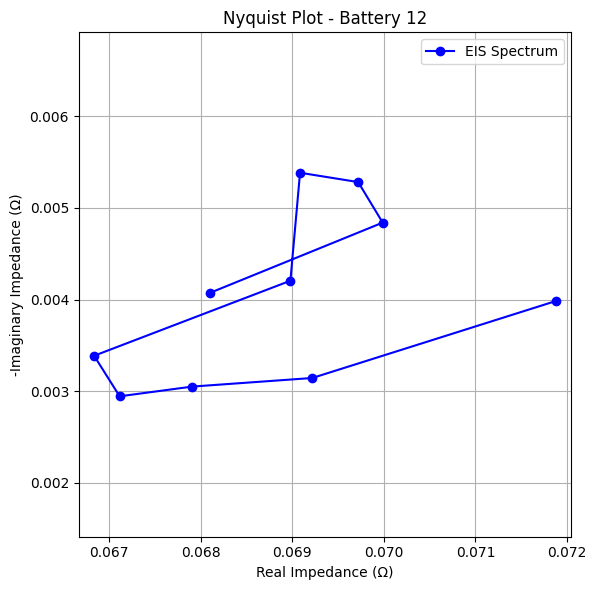

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Function to convert string to complex number
def str_to_complex(s):
    return complex(s.replace('i', 'j'))
                                                            
# Load CSV
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# Convert strings to complex numbers
impedance_data = df.applymap(str_to_complex)

# Example: Plotting one EIS spectrum (first row)
example_spectrum = impedance_data.iloc[0].values

# Extract real and imaginary parts
real_part = [z.real for z in example_spectrum]
imag_part = [-z.imag for z in example_spectrum]  # Negative Im(Z) is standard

# Plot Nyquist plot
plt.figure(figsize=(6, 6))
plt.plot(real_part, imag_part, 'o-', label="EIS Spectrum", color='blue')
plt.xlabel("Real Impedance (Ω)")
plt.ylabel("-Imaginary Impedance (Ω)")
plt.title("Nyquist Plot - Battery 12")
plt.grid(True)
plt.axis('equal')  # Equal axis scaling
plt.legend()
plt.tight_layout()
plt.show()

Data Preprocessing

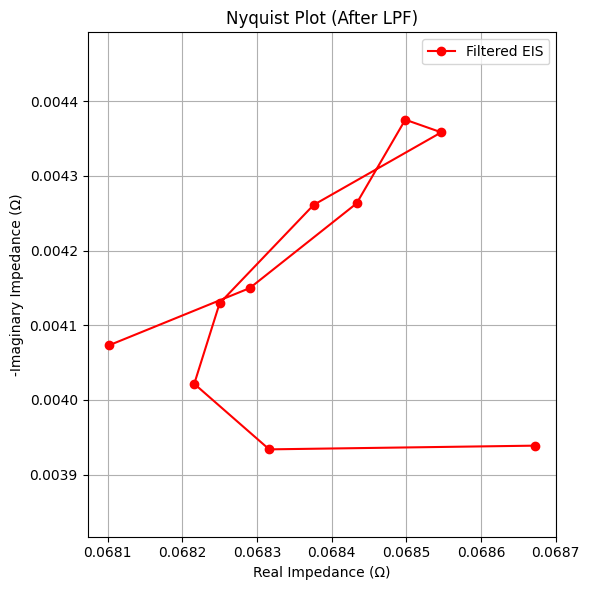

In [4]:
def low_pass_filter(signal, alpha=0.1):
    """Applies a simple exponential moving average filter"""
    filtered = np.zeros_like(signal, dtype=complex)
    filtered[0] = signal[0]
    for i in range(1, len(signal)):
        filtered[i] = alpha * signal[i] + (1 - alpha) * filtered[i-1]
    return filtered

# Apply LPF to each row
filtered_data = impedance_data.apply(lambda row: low_pass_filter(np.array(row)), axis=1)

# Example: Plot one filtered spectrum
example_filtered = filtered_data.iloc[0]
real_filt = [z.real for z in example_filtered]
imag_filt = [-z.imag for z in example_filtered]

plt.figure(figsize=(6, 6))
plt.plot(real_filt, imag_filt, 'o-', label="Filtered EIS", color='red')
plt.title("Nyquist Plot (After LPF)")
plt.xlabel("Real Impedance (Ω)")
plt.ylabel("-Imaginary Impedance (Ω)")
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.tight_layout()
plt.show()

Feature Isolation

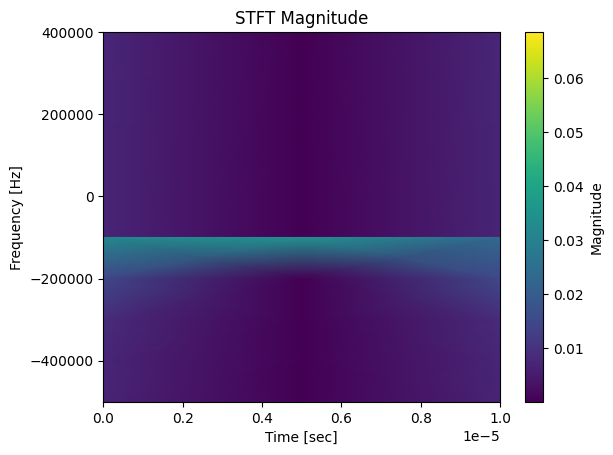

In [5]:
from scipy.signal import stft

def lstft(signal, fs=1e6):
    f, t, Zxx = stft(signal, fs=fs, nperseg=10, return_onesided=False)
    return f, t, Zxx

# Apply STFT to one EIS spectrum
example_spectrum = filtered_data[0]  # Get the first row of the array
frequencies, times, stft_result = lstft(example_spectrum)

# Plot STFT Magnitude
plt.pcolormesh(times, frequencies, np.abs(stft_result), shading='gouraud')
plt.title("STFT Magnitude")
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
plt.colorbar(label='Magnitude')
plt.show()

Peak Detection

In [6]:
from scipy.signal import find_peaks

# Assuming stft_result is your STFT magnitude
magnitude = np.abs(stft_result)

# Flatten the magnitude array to detect peaks
flat_magnitude = magnitude.flatten()

# Detect peaks
peaks, _ = find_peaks(flat_magnitude, height=0.03)  # Adjust height threshold as needed

# Extract peak features
peak_amplitudes = flat_magnitude[peaks]
peak_frequencies = frequencies[peaks % len(frequencies)]  # Map back to frequency domain
peak_phases = times[peaks // len(frequencies)]  # Map back to time domain

print("Detected Peaks:")
print("Amplitudes:", peak_amplitudes)
print("Frequencies:", peak_frequencies)
print("Phases:", peak_phases)

Detected Peaks:
Amplitudes: [0.06851233 0.03434421 0.03416861]
Frequencies: [ 100000.  400000. -200000.]
Phases: [0.e+00 0.e+00 1.e-05]


Detected peaks at indices: [4]
Corresponding Frequencies (Hz): [464.15888336]
Corresponding Magnitudes: [0.06868511]


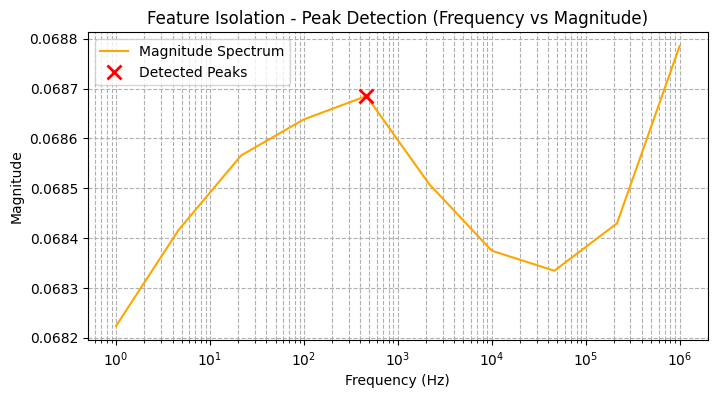

In [20]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

magnitude = np.abs(example_spectrum)  # Magnitude of EIS signal

# Generate artificial frequency axis: 1Hz to 1MHz (common in EIS)
freq = np.logspace(0, 6, len(magnitude))  # 1 to 1,000,000 Hz, logarithmic scale

# Detect peaks
peaks, properties = find_peaks(magnitude)

print("Detected peaks at indices:", peaks)
print("Corresponding Frequencies (Hz):", freq[peaks])
print("Corresponding Magnitudes:", magnitude[peaks])

# Plot detected peaks
plt.figure(figsize=(8, 4))
plt.semilogx(freq, magnitude, label='Magnitude Spectrum', color='orange')  # semilog x-axis
plt.plot(freq[peaks], magnitude[peaks], "x", label='Detected Peaks', color='red', markersize=10, markeredgewidth=2)
plt.title("Feature Isolation - Peak Detection (Frequency vs Magnitude)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

Cluster EIS Spectra Using K-Means

In [7]:
from sklearn.cluster import KMeans
from scipy import stats

# Load preprocessed EIS data
with open('filtered_data.pkl', 'rb') as f:
    filtered_data = pickle.load(f)

# Function to extract peak features from each spectrum
def extract_peak_features(z_values):
    magnitude = np.abs(z_values)
    phase = np.angle(z_values)

    peaks, _ = find_peaks(magnitude, height=np.mean(magnitude) + 0.5 * np.std(magnitude))

    if len(peaks) == 0:
        return None  # Skip if no peak found

    max_idx = peaks[np.argmax(magnitude[peaks])]  # Peak with highest amplitude

    return {
        'Amplitude': magnitude[max_idx],
        'Frequency_Index': max_idx,
        'Phase_At_Peak': phase[max_idx],
        'Skewness': stats.skew(magnitude),
        'Kurtosis': stats.kurtosis(magnitude),
        'Peak_Shape': np.mean(magnitude[max(max_idx-2, 0):max(max_idx+3, len(magnitude))])
    }

# Apply feature extraction to all rows
peak_features_list = []
for idx, row in enumerate(filtered_data.values):
    features = extract_peak_features(row)
    if features:
        features['Spectrum_Index'] = idx
        peak_features_list.append(features)

# Convert list to DataFrame
features_df = pd.DataFrame(peak_features_list)
print("Extracted Peak Features:\n", features_df.head())

# Cluster using K-means
kmeans = KMeans(n_clusters=3, random_state=42)
features_df['Cluster'] = kmeans.fit_predict(features_df[['Amplitude', 'Skewness', 'Kurtosis']])
print("\nFirst 10 Cluster Labels:")
print(features_df[['Spectrum_Index', 'Amplitude', 'Cluster']].head(10))

Extracted Peak Features:
    Amplitude  Frequency_Index  Phase_At_Peak  Skewness  Kurtosis  Peak_Shape  \
0   0.068685                4      -0.063496  0.157127 -0.925672    0.068540   
1   0.067569                2      -0.045247 -0.303971 -1.466127    0.067409   
2   0.066727                2      -0.032918 -0.259499 -1.670424    0.066509   
3   0.066132                1      -0.024990 -0.171913 -1.544531    0.065965   
4   0.065434                1      -0.023989 -0.051090 -1.540705    0.065248   

   Spectrum_Index  
0               0  
1               1  
2               2  
3               3  
4               4  

First 10 Cluster Labels:
   Spectrum_Index  Amplitude  Cluster
0               0   0.068685        1
1               1   0.067569        0
2               2   0.066727        0
3               3   0.066132        0
4               4   0.065434        2
5               5   0.064982        2
6               6   0.064323        2


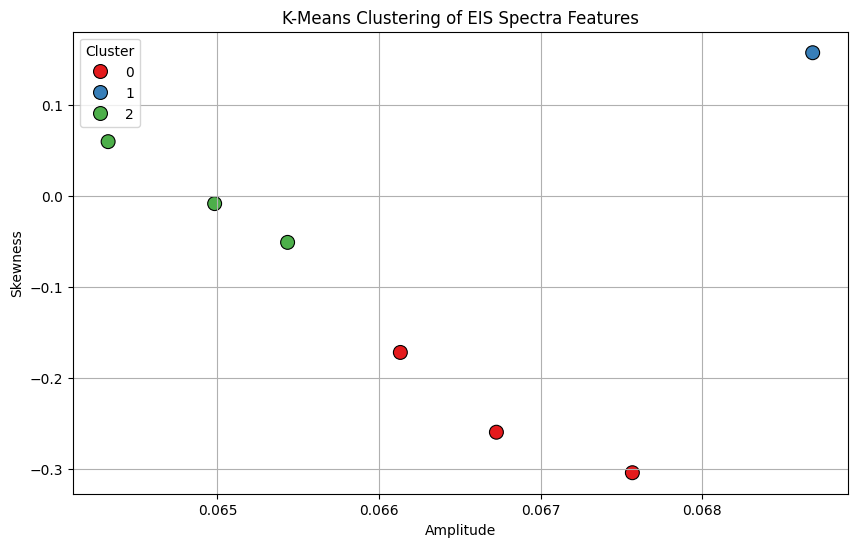

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the clusters based on Amplitude and Skewness
plt.figure(figsize=(10, 6))
sns.scatterplot(data=features_df, 
                x='Amplitude', 
                y='Skewness', 
                hue='Cluster', 
                palette='Set1', 
                s=100, 
                edgecolor='k')

plt.title('K-Means Clustering of EIS Spectra Features')
plt.xlabel('Amplitude')
plt.ylabel('Skewness')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

Granger Causality Mapping

In [8]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR

# Simulate a defect indicator (replace with real degradation labels later)
np.random.seed(42)
defect_indicator = np.random.normal(0, 0.1, size=len(features_df))
defect_indicator[::3] += 0.5  # Artificial correlation every few points

# Combine features and simulated defect indicator
data = pd.DataFrame({
    'Amplitude': features_df['Amplitude'],
    'Skewness': features_df['Skewness'],
    'Kurtosis': features_df['Kurtosis'],
    'Defect_Indicator': defect_indicator
})

# Drop any rows with missing values
data.dropna(inplace=True)

# Fit VAR model
model = VAR(data)
results = model.fit(2)  # Lag order = 2

# Perform Granger causality test
print("Granger Causality Test Results:")
causality_test = results.test_causality('Defect_Indicator', ['Amplitude', 'Skewness', 'Kurtosis'])
print(causality_test.summary())

Granger Causality Test Results:
Granger causality F-test. H_0: ['Amplitude', 'Skewness', 'Kurtosis'] do not Granger-cause Defect_Indicator. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
    -1.038e+28            nan     NAN (6, -16)
----------------------------------------------


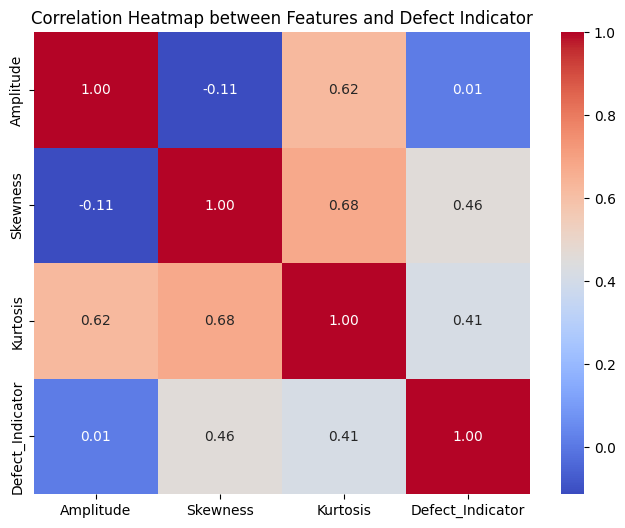

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr_matrix = data.corr()

# Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap between Features and Defect Indicator')
plt.show()

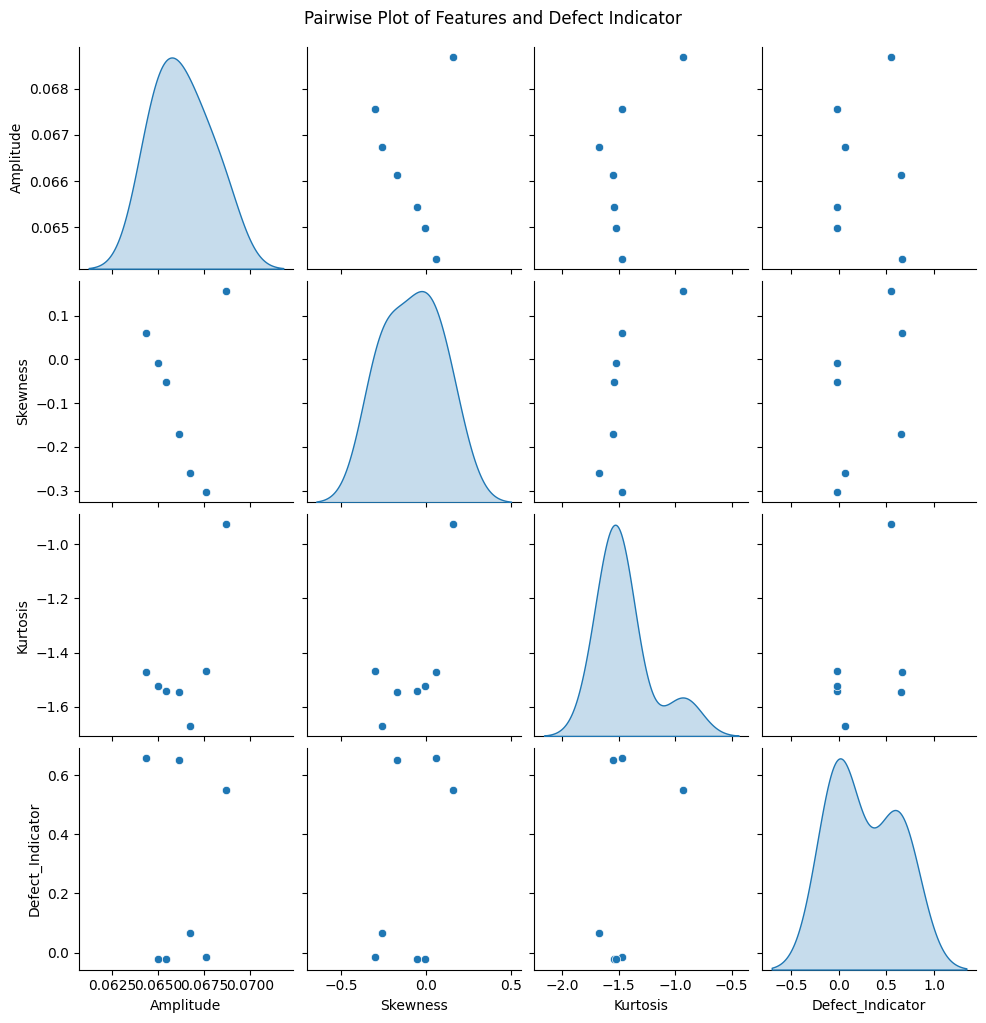

In [14]:
sns.pairplot(data, diag_kind='kde', hue=None)
plt.suptitle('Pairwise Plot of Features and Defect Indicator', y=1.02)
plt.show()

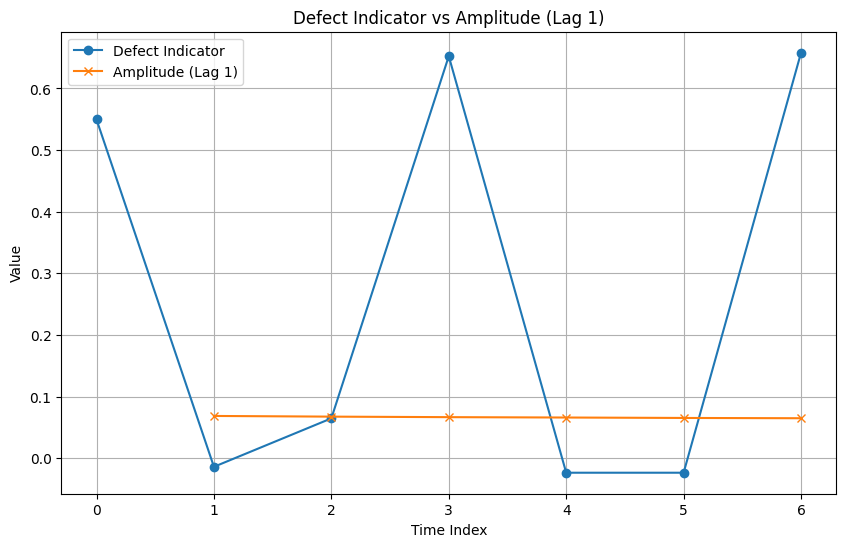

In [15]:
plt.figure(figsize=(10,6))
plt.plot(data['Defect_Indicator'].values, label='Defect Indicator', marker='o')
plt.plot(data['Amplitude'].shift(1).values, label='Amplitude (Lag 1)', marker='x')
plt.legend()
plt.title('Defect Indicator vs Amplitude (Lag 1)')
plt.xlabel('Time Index')
plt.ylabel('Value')
plt.grid(True)
plt.show()

DRT Analysis Using FTRM

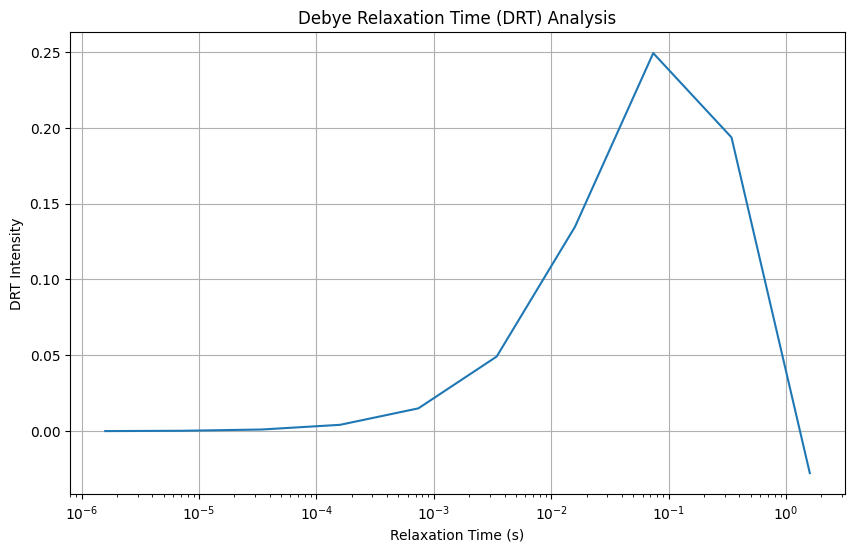

In [9]:
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import spsolve

# Simulate frequency vector (replace with real values if available)
y = np.logspace(np.log10(0.1), np.log10(1e5), num=10)  # Frequencies from 0.1 Hz to 100 kHz
C = 1 / (2 * np.pi * y)  # Capacitance equivalent

# Simulated impedance data from previous steps
Z = []  # Replace with actual impedance values from your preprocessed data
for idx, row in enumerate(filtered_data.values):
    magnitude = np.abs(row)
    Z.append(magnitude)

Z = np.array(Z).mean(axis=0)  # Take average across all rows for simplicity

# Build system matrix M for DRT calculation
def build_M(y, Z):
    N = len(y)
    M = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            M[i, j] = (1 / (1 + (2 * np.pi * y[i] * C[j])**2)) * C[j]
    return M

M = build_M(y, Z)

# Solve using Foxholes Tikhonov Regularization Method (FTRM)
lambda_reg = 0.01  # Regularization parameter
A = np.dot(M.T, M) + lambda_reg * np.eye(M.shape[1])
b = np.dot(M.T, Z)

# Solve for DRT
drt = np.linalg.solve(A, b)

# Plot DRT
plt.figure(figsize=(10, 6))
plt.plot(C, drt)
plt.xscale('log')
plt.title("Debye Relaxation Time (DRT) Analysis")
plt.xlabel("Relaxation Time (s)")
plt.ylabel("DRT Intensity")
plt.grid(True)
plt.show()

Voltage Perturbation Analysis

In [10]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Simulate voltage measurements (replace with your actual data)
voltage_measurements = [
    "0.0681016826829699-0.00407308837639501i",
    "0.069987765419671-0.00484005261496363i",
    "0.0697201098016747-0.00528268621404753i",
    "0.0690856426968521-0.00538435733522175i",
    "0.0689803488674355-0.00420589393906668i",
    "0.0668382093180645-0.00338697564282288i",
    "0.067117012339535-0.00294460040282523i",
    "0.0679105367844506-0.00305075996294583i",
    "0.0692195666833384-0.0031444883986299i",
    "0.0718751317014823-0.00398364137674741i"
]

# Replace 'i' with 'j' to make it compatible with complex()
voltage_measurements_fixed = [val.replace('i', 'j') for val in voltage_measurements]

# Convert strings to complex numbers
voltage_measurements_complex = np.array([complex(val) for val in voltage_measurements_fixed])

# Extract real part for normalization
real_part = voltage_measurements_complex.real

# Normalize voltage data
scaler = MinMaxScaler()
normalized_voltage = scaler.fit_transform(real_part.reshape(-1, 1)).flatten()

print("Normalized Voltage:", normalized_voltage)

# Apply CWN-FLS (simplified version)
def cwn_fls(voltage):
    # Fuzzification (example: simple Gaussian membership function)
    def gaussian_membership(x, mean, std):
        return np.exp(-(x - mean)**2 / (2 * std**2))
    
    # Define fuzzy sets
    low_risk = gaussian_membership(normalized_voltage, mean=0.2, std=0.1)
    medium_risk = gaussian_membership(normalized_voltage, mean=0.5, std=0.1)
    high_risk = gaussian_membership(normalized_voltage, mean=0.8, std=0.1)
    
    # Rule base (simple example)
    risk_levels = np.maximum(low_risk, np.maximum(medium_risk, high_risk))
    
    # Defuzzification using cosine whitening normalization
    mv = np.mean(risk_levels)
    defuzzified_risk = np.cos(np.pi * (risk_levels - mv) / np.std(risk_levels))
    
    return defuzzified_risk

# Analyze voltage perturbations
voltage_perturbation_analysis = cwn_fls(normalized_voltage)
print("Voltage Perturbation Risk Levels:", voltage_perturbation_analysis[:5])

Normalized Voltage: [0.25084233 0.62529375 0.57215503 0.44619178 0.42528739 0.
 0.05535186 0.21289339 0.47278024 1.        ]
Voltage Perturbation Risk Levels: [-0.7865174  -0.16675816  0.17051055 -0.69628135  0.30921329]
